In [56]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC

In [57]:
#Step 1: Dataset choice
#This is Bank marketing database
#Link:https://archive.ics.uci.edu/dataset/222/bank+marketing

In [58]:
df = pd.read_csv('bank-additional-full.csv', sep=',')

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [59]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df['y'].value_counts())

Dataset dimensions: (41188, 21)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Missing values:
0

Target distribution:
no     36548
yes     4640
Name: y, dtype: int64


In [60]:
# We have to prioritize Yes who are only 11%. So, accuracy of almost 90% can
# be achieved by simply answering everything as a No
# The evaluation metric to prioritize is 'Recall'

In [61]:
#Step 2: Machine Learning Classification models and Evaluation metrics

In [62]:
#Data Analysis
#Remove any duplicates
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicate rows:", df.duplicated().sum())

#Encoding
#Feature dataframe
X = df.drop(columns=['y', 'duration'])
#target dataframe with encoding
y = df['y'].map({'no': 0, 'yes': 1})

#Identify categorical columns
categorical_cols = X.select_dtypes(include='object').columns
X = pd.get_dummies(X, columns=categorical_cols, dtype=int)

print("Feature dimensions:", X.shape)
print("Target dimensions:", y.shape)

print("\nRemaining categorical columns:")
print(X.select_dtypes(include='object').columns.tolist())

X.head()

Duplicate rows: 0
Feature dimensions: (41176, 62)
Target dimensions: (41176,)

Remaining categorical columns:
[]


,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,job_admin.,...,month_oct,month_sep,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success
0,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,0,0,0,1,0,0,0,0,1,0
1,57,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,0,0,0,1,0,0,0,0,1,0
2,37,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,0,0,0,1,0,0,0,0,1,0
3,40,1,999,0,1.1,93.994,-36.4,4.857,5191.0,1,...,0,0,0,1,0,0,0,0,1,0
4,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0,0,...,0,0,0,1,0,0,0,0,1,0


In [63]:
#Train-Test Split @ 80-20 with stratify y so that train test has comparable outcome distribution
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (32940, 62)
Testing set: (8236, 62)

Training target distribution:
0    0.887341
1    0.112659
Name: y, dtype: float64

Testing target distribution:
0    0.887324
1    0.112676
Name: y, dtype: float64


In [64]:
#Scaling the features for efficient optimization convergence
#using standard scaler
#Scaling is unnecessary for Decision Trees and Gauss NB
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data:", X_train_scaled.shape)
print("Testing data:", X_test_scaled.shape)

Training data: (32940, 62)
Testing data: (8236, 62)


In [65]:
#Model functions
models = {
    # Balanced class weight for better performance
    'Logistic Regression': LogisticRegression(max_iter=1000,class_weight='balanced'),

    'Decision Tree': DecisionTreeClassifier(random_state=0,class_weight='balanced'),

    'KNN': KNeighborsClassifier(n_neighbors=5),

    'Naive Bayes': GaussianNB(),

    'SVM': LinearSVC(dual=False,max_iter=1000, random_state=0,class_weight='balanced')
}

In [66]:
# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

In [67]:
#Model Training
for name, model in models.items():
    # Only Logistic Reg, KNN and SVM need scaled data
    # Decision Tree and Gauss NB does not need scaling
    if name in ['Logistic Regression', 'KNN', 'SVM']:
        model.fit(X_train_scaled, y_train)

    else:
        model.fit(X_train, y_train)

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
KNN trained successfully
Naive Bayes trained successfully
SVM trained successfully


In [68]:
results = []

for name, model in models.items():

    if name in ['Logistic Regression', 'KNN', 'SVM']:
        X_eval = X_test_scaled
    else:
        X_eval = X_test

    y_pred = model.predict(X_eval)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_eval)[:, 1]
    else:
        y_score = model.decision_function(X_eval)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'AUC': roc_auc_score(y_test, y_score),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'MCC': matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8305,0.7920,0.3571,0.6304,0.4560,0.3852
1,Decision Tree,0.8436,0.6186,0.3140,0.3276,0.3207,0.2324
2,KNN,0.8887,0.7158,0.5118,0.2565,0.3417,0.3088
3,Naive Bayes,0.8517,0.7725,0.3755,0.4763,0.4200,0.3395
4,SVM,0.8300,0.7914,0.3563,0.6304,0.4553,0.3844


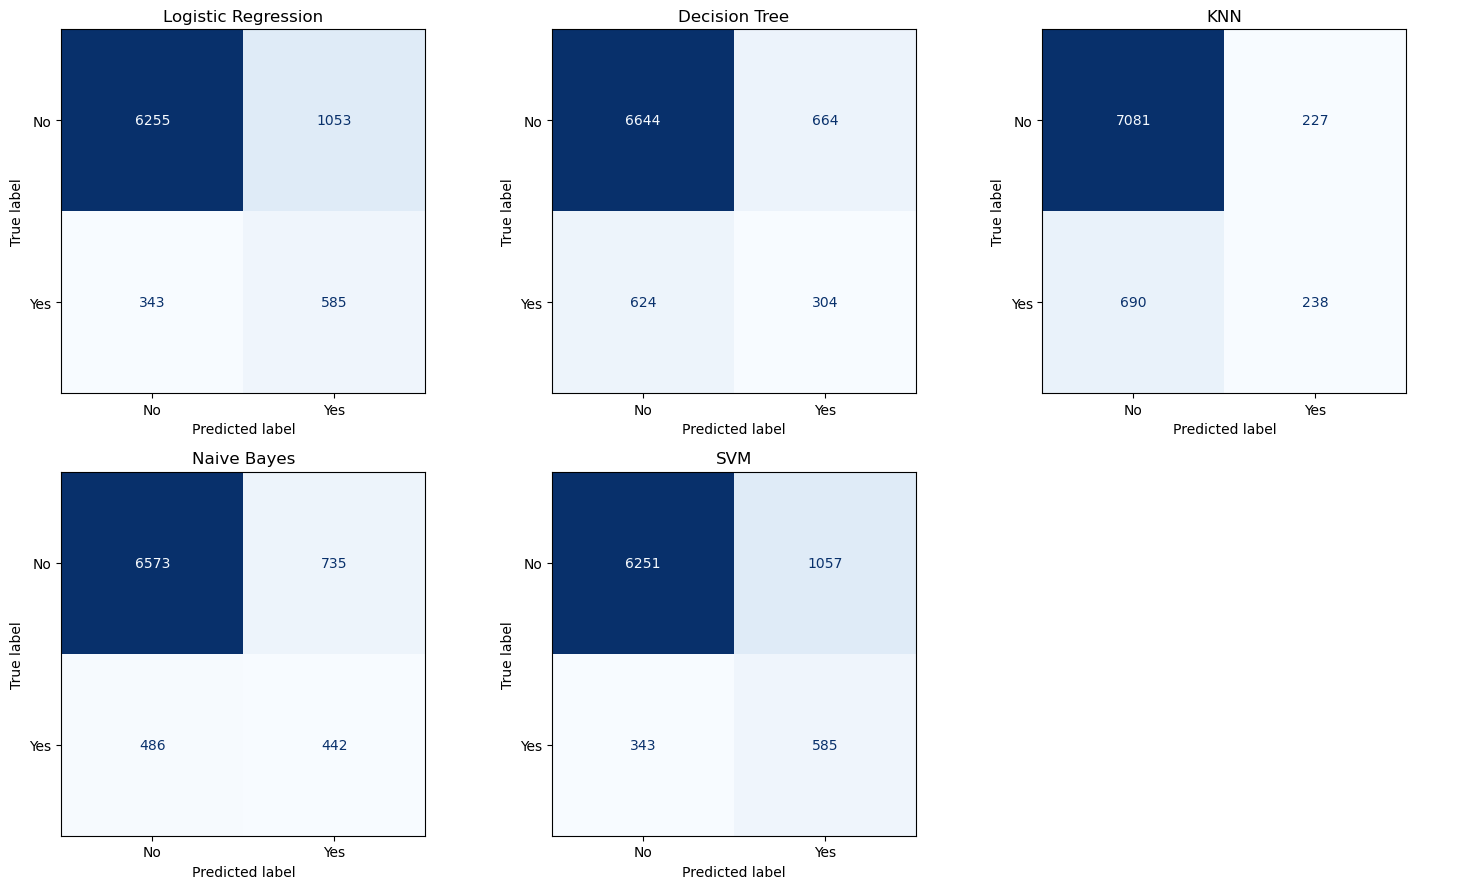

In [69]:
#Draw confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for i, (name, model) in enumerate(models.items()):

    if name in ['Logistic Regression', 'KNN', 'SVM']:
        X_eval = X_test_scaled
    else:
        X_eval = X_test

    y_pred = model.predict(X_eval)

    cm = confusion_matrix(y_test, y_pred)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No', 'Yes']
    )

    disp.plot(ax=axes.flat[i], cmap='Blues', colorbar=False)
    axes.flat[i].set_title(name)

axes.flat[5].axis('off')

plt.tight_layout()
plt.show()